# 视频按帧率抽帧（JupyterLab / VSCode）

从 `仿真演示.mp4` 按指定帧率抽取图片，保存到本文件夹。内核选 `Python (yolo_new)`。

> 注意：Windows 中文路径下 `cv2.imwrite` 会静默失败，本 Notebook 统一用 **PIL** 保存，避免踩坑。

In [11]:
import os
import cv2
from PIL import Image, ImageDraw
from IPython.display import display

# ==================== 参数配置 ====================
FOLDER = r'D:\projects\yolo_demo'   # 视频所在文件夹，图片也存这里
VIDEO_NAME = 'simulation.mp4'
EXTRACT_FPS = 0.2                    # 每秒抽取张数：1=每秒1张，2=每秒2张，30=每帧都存
IMAGE_EXT = '.jpg'
SAVE =  r'D:\projects\yolo_demo\demo_iamges'
# ==================================================

video_path = os.path.join(FOLDER, VIDEO_NAME)
print('视频路径：', video_path)

视频路径： D:\projects\yolo_demo\simulation.mp4


## 1. 查看视频信息

In [12]:
cap = cv2.VideoCapture(video_path)
assert cap.isOpened(), f'无法打开视频：{video_path}'

src_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = total / src_fps

print(f'源帧率：{src_fps:.2f} FPS')
print(f'总帧数：{total} 帧 | 分辨率：{width}x{height} | 时长：{duration:.1f} 秒')
print(f'抽帧率：每秒 {EXTRACT_FPS} 张，预计约 {int(duration * EXTRACT_FPS)} 张')
cap.release()

源帧率：30.00 FPS
总帧数：1374 帧 | 分辨率：1280x720 | 时长：45.8 秒
抽帧率：每秒 0.2 张，预计约 9 张


## 2. 按帧率抽帧并保存

In [13]:
cap = cv2.VideoCapture(video_path)
step = max(3, round(src_fps / EXTRACT_FPS))   # 每隔多少源帧取 1 张

count = 0
frame_idx = 0
saved = []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    if frame_idx % step == 0:
        count += 1
        sec = frame_idx / src_fps
        name = f'frame_{count:04d}_{sec:06.2f}s{IMAGE_EXT}'
        # 中文路径用 PIL 保存（cv2.imwrite 会静默失败）
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        Image.fromarray(rgb).save(os.path.join(SAVE, name))
        saved.append((name, sec))
    frame_idx += 1

cap.release()
print(f'完成！共保存 {count} 张图片到：{SAVE}')

完成！共保存 10 张图片到：D:\projects\yolo_demo\demo_iamges


## 3. 预览抽取结果（拼成缩略图网格）

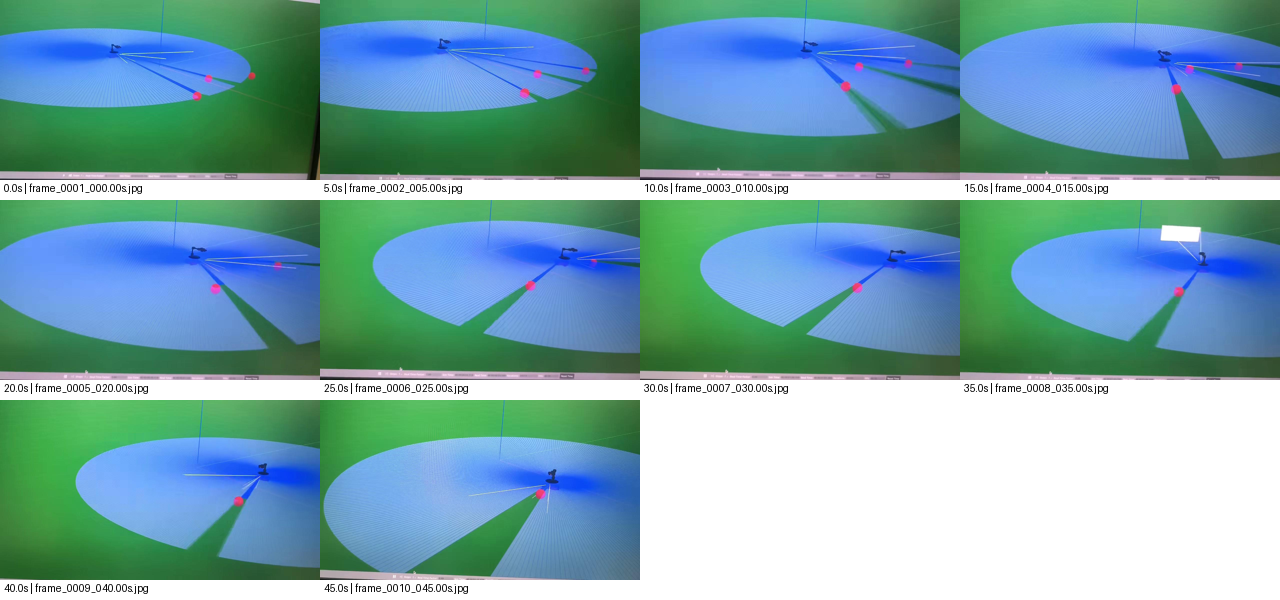

In [14]:
# 均匀取最多 16 张做预览
import math
pick = saved[::max(1, len(saved) // 16)][:16]
thumb_w, thumb_h = 320, 180
cols = 4
rows = math.ceil(len(pick) / cols)
sheet = Image.new('RGB', (cols * thumb_w, rows * (thumb_h + 20)), 'white')
draw = ImageDraw.Draw(sheet)

for i, (name, sec) in enumerate(pick):
    img = Image.open(os.path.join(FOLDER, name)).resize((thumb_w, thumb_h))
    x, y = (i % cols) * thumb_w, (i // cols) * (thumb_h + 20)
    sheet.paste(img, (x, y))
    draw.text((x + 4, y + thumb_h + 2), f'{sec:.1f}s | {name}', fill='black')

display(sheet)